# 03 — CNN desde cero: efecto de pesos de clase

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MiltonCuervo/ham10000-skin-lesion-classification/blob/main/03_arquitectura_linea_base.ipynb)

Ejecución local: abre Jupyter desde la carpeta del proyecto y selecciona **Python (HAM10000 local GPU)**. Ejecuta en orden 01–05. Los resultados se guardan localmente; no se monta Drive. En Colab, usa `/content` como carpeta del proyecto y ejecuta primero 01 y 02.


## Resultados finales de test verificados

Modelo: **CNN desde cero con pesos de clase**. Selección realizada previamente mediante validación (balanced accuracy: 0.7492). Evaluación sobre **1.494 imágenes de test**, con lesiones separadas de entrenamiento y validación.

| Métrica de test | Resultado |
|---|---:|
| Balanced accuracy | 0.7865 |
| F1 macro | 0.6687 |
| AUC-ROC binaria | 0.8649 |
| Accuracy | 0.6981 |

Métricas contrastadas con las predicciones guardadas y el checkpoint seleccionado. Las curvas de aprendizaje, la matriz de confusión y la ROC permanecen en las salidas del notebook. La revisión no reentrenó ni modificó la selección usando test.

El grupo positivo reúne `mel`, `bcc` y `akiec`: sensibilidad **94.03%**, precisión **40.90%**. Se identificaron 299 de 318 imágenes positivas; hubo **19 falsos negativos** y **432 falsos positivos**. Esta sensibilidad corresponde al grupo maligno o premaligno, no a una clasificación exclusiva de melanoma.


## 1. Configuración local

In [1]:
from pathlib import Path
import os, json, hashlib, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
PROJECT = Path.cwd().resolve()  # Abrir Jupyter desde la carpeta del proyecto.
DATA = PROJECT/'data'/'ham10000'
SPLITS = PROJECT/'data'/'splits'
CACHE = PROJECT/'data'/'processed_224'
SEED = 42
CLASSES = ['akiec','bcc','bkl','df','mel','nv','vasc']
POSITIVE = {'mel','bcc','akiec'}

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, roc_curve
MODE = 'full'  # 'smoke': muestra mínima para comprobar el código, sin test final.
RUN_ID = 'local_v2'  # Cambiar si modificas arquitectura, resolución o hiperparámetros.
BATCH_SIZE = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda' and torch.cuda.get_device_capability(0)[0] >= 7
# La GTX 1050 usa FP32: no tiene Tensor Cores.
torch.set_num_threads(2)
assert MODE in {'full','smoke'}
RUNS = PROJECT/'results'/MODE/RUN_ID
RUNS.mkdir(parents=True, exist_ok=True)
print('PyTorch:',torch.__version__, '| Dispositivo:',DEVICE,
      '| GPU:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'ninguna', '| AMP:',AMP)

PyTorch: 2.6.0+cu118 | Dispositivo: cuda | GPU: NVIDIA GeForce GTX 1050 | AMP: False


## 2. Dataset y cargadores

Solo entrenamiento usa aumento. Los pesos se calculan únicamente con train. MODE smoke comprueba el código con una muestra pequeña; sus resultados van a otro directorio.

In [2]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if DEVICE.type == 'cuda': torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def load_partitions(multiclass=False):
    info = json.loads((SPLITS/'manifest_local.json').read_text())
    raw = {n:pd.read_csv(SPLITS/f'{n}.csv')[['image_id','lesion_id','dx']] for n in ['train','valid','test']}
    fingerprint=hashlib.sha256(json.dumps({n:f.to_dict('records') for n,f in raw.items()},sort_keys=True).encode()).hexdigest()
    assert fingerprint==info['split_hash'], 'Los manifiestos cambiaron: ejecuta 02 y usa otro RUN_ID.'
    frames = {}
    for split in ['train','valid','test']:
        frame = raw[split].copy()
        frame['target'] = frame.dx.map(dict(zip(CLASSES, range(7)))) if multiclass else frame.dx.isin(POSITIVE).astype(int)
        frame['path'] = frame.image_id.map(lambda name: CACHE/f'{name}.png')
        assert frame.path.map(Path.is_file).all(), 'Ejecuta primero el notebook 02.'
        if MODE == 'smoke' and split != 'test':
            frame = pd.concat([g.sample(min(4,len(g)),random_state=SEED) for _,g in frame.groupby('target')])
        frames[split] = frame.reset_index(drop=True)
    for a,b in [('train','valid'),('train','test'),('valid','test')]:
        assert set(frames[a].lesion_id).isdisjoint(frames[b].lesion_id)
    return frames, info

class LesionDataset(Dataset):
    def __init__(self, frame, augment=False):
        self.frame = frame
        steps = [transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(), transforms.RandomRotation(20)] if augment else []
        self.transform = transforms.Compose(steps + [transforms.ToTensor(), transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(row.path) as image: x = self.transform(image.convert('RGB'))
        return x, int(row.target)

def make_loader(frame, train=False, epoch=0):
    generator = torch.Generator().manual_seed(SEED+epoch)
    return DataLoader(LesionDataset(frame,train),batch_size=BATCH_SIZE,shuffle=train,
                      num_workers=0,pin_memory=DEVICE.type=='cuda',generator=generator)

In [3]:
frames,data_info=load_partitions()
n_classes=2
class_names=['benigna','maligna_o_premaligna']
print({name:len(f) for name,f in frames.items()})

{'train': 7002, 'valid': 1519, 'test': 1494}


## 3. Arquitectura

Tres bloques convolucionales pequeños y pooling global. Entrada RGB 224×224; dos logits. El grupo positivo incluye mel, bcc y akiec.

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, classes=2):
        super().__init__(); blocks=[]; channels=3
        for out in [16,32,64]:
            blocks += [nn.Conv2d(channels,out,3,padding=1),nn.BatchNorm2d(out),nn.ReLU(),nn.MaxPool2d(2)]
            channels=out
        self.network=nn.Sequential(*blocks,nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.3),nn.Linear(64,classes))
    def forward(self,x): return self.network(x)

## 4. Entrenamiento y validación

Se guarda un checkpoint por época para reanudar y el mejor modelo por balanced accuracy de validación. Dos experimentos con la misma semilla: sin pesos y con pesos. Los checkpoints previos de local_v1/Colab no se reutilizan.

In [5]:
def fit(model, frames, folder, epochs, lr, weighted, architecture, stage='all', train_modules=None):
    folder.mkdir(parents=True,exist_ok=True)
    settings = dict(version='local_v2',architecture=architecture,stage=stage,epochs=epochs,lr=lr,
                    weighted=weighted,classes=n_classes,batch_size=BATCH_SIZE,seed=SEED,mode=MODE,
                    data=data_info,torch=torch.__version__,amp=AMP,
                    trainable=[n for n,p in model.named_parameters() if p.requires_grad])
    signature = hashlib.sha256(json.dumps(settings,sort_keys=True).encode()).hexdigest()
    if (folder/'config.json').exists():
        assert json.loads((folder/'config.json').read_text())['signature']==signature, 'Configuración distinta: cambia RUN_ID.'
    (folder/'config.json').write_text(json.dumps({'signature':signature,**settings},indent=2))
    counts = np.bincount(frames['train'].target,minlength=n_classes)
    weights = torch.tensor(len(frames['train'])/(n_classes*counts),dtype=torch.float32,device=DEVICE) if weighted else None
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],lr=lr)
    scaler = torch.amp.GradScaler('cuda',enabled=AMP)
    start, history, best = 0, [], -1.
    if (folder/'last.pt').exists():
        state = torch.load(folder/'last.pt',map_location=DEVICE,weights_only=False)
        assert state['signature']==signature
        model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer']); scaler.load_state_dict(state['scaler'])
        start,history,best = state['epoch']+1,state['history'],state['best']
        del state
        print('Reanudando',architecture,stage,'desde época',start+1)
    for epoch in range(start,epochs):
        seed_everything(SEED+epoch); started=time.perf_counter()
        model.train() if train_modules is None else model.eval()
        for module in train_modules or []: module.train()
        totals, predictions, targets = {}, [], []
        for split in ['train','valid']:
            training = split=='train'
            if not training: model.eval()
            total_loss, total_images = 0., 0
            for x,y in tqdm(make_loader(frames[split],training,epoch),desc=f'{architecture} {stage} {epoch+1}/{epochs} {split}',leave=False):
                x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
                if training: optimizer.zero_grad(set_to_none=True)
                with torch.set_grad_enabled(training), torch.autocast(device_type=DEVICE.type,enabled=AMP):
                    logits=model(x); loss=criterion(logits,y)
                if not torch.isfinite(loss): raise RuntimeError('Pérdida no finita: revisar datos y LR.')
                if training:
                    scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                else:
                    predictions.extend(logits.argmax(1).detach().cpu().tolist()); targets.extend(y.cpu().tolist())
                total_loss+=loss.item()*len(y); total_images+=len(y)
            totals[split+'_loss']=total_loss/total_images
        score=balanced_accuracy_score(targets,predictions)
        history.append(dict(epoch=epoch+1,**totals,valid_balanced_accuracy=score,
                            valid_f1_macro=f1_score(targets,predictions,average='macro',zero_division=0),seconds=time.perf_counter()-started))
        if score>best:
            best=score; best_temp=folder/'best.tmp'
            torch.save({'model':model.state_dict(),'signature':signature,'score':float(score)},best_temp); os.replace(best_temp,folder/'best.pt')
        state=dict(model=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
                   epoch=epoch,history=history,best=best,signature=signature)
        temp=folder/'last.tmp'; torch.save(state,temp); os.replace(temp,folder/'last.pt')
        pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
        print(history[-1],flush=True)
    checkpoint=torch.load(folder/'best.pt',map_location=DEVICE,weights_only=False)
    model.load_state_dict(checkpoint['model'])
    return dict(model=architecture,stage=stage,folder=str(folder),signature=signature,
                balanced_accuracy=float(checkpoint['score']),mode=MODE), pd.DataFrame(history)

In [6]:
EPOCHS=10 if MODE=='full' else 1
rows=[]; histories={}
for weighted in [False,True]:
    seed_everything(); model=SmallCNN().to(DEVICE)
    label='con_pesos' if weighted else 'sin_pesos'
    chosen,history=fit(model,frames,RUNS/'baseline'/label,EPOCHS,1e-3,weighted,'small_cnn')
    rows.append(chosen); histories[label]=history
    del model
    if DEVICE.type=='cuda': torch.cuda.empty_cache()
selected=max(rows,key=lambda row:row['balanced_accuracy'])
(RUNS/'baseline_selected.json').write_text(json.dumps(selected,indent=2))
display(pd.DataFrame(rows)[['folder','balanced_accuracy']])

{'epoch': 1, 'train_loss': 0.4482055699457546, 'valid_loss': 0.4159814822558041, 'valid_balanced_accuracy': 0.5, 'valid_f1_macro': 0.44963768115942027, 'seconds': 64.44321570000102}


{'epoch': 2, 'train_loss': 0.4371081390182688, 'valid_loss': 0.39701562386602063, 'valid_balanced_accuracy': 0.5017985611510791, 'valid_f1_macro': 0.4533848818009746, 'seconds': 58.94747970000026}


{'epoch': 3, 'train_loss': 0.4322722700792393, 'valid_loss': 0.3962261437329907, 'valid_balanced_accuracy': 0.5, 'valid_f1_macro': 0.44963768115942027, 'seconds': 60.90676969999913}


{'epoch': 4, 'train_loss': 0.42312236318364205, 'valid_loss': 0.38590201677127917, 'valid_balanced_accuracy': 0.5580568583006278, 'valid_f1_macro': 0.5624105112890979, 'seconds': 58.172806800001126}


{'epoch': 5, 'train_loss': 0.4170518676635709, 'valid_loss': 0.38749941751861194, 'valid_balanced_accuracy': 0.5724453475092609, 'valid_f1_macro': 0.5837547836403437, 'seconds': 59.514441300001636}


{'epoch': 6, 'train_loss': 0.4077574413219747, 'valid_loss': 0.3761879225274385, 'valid_balanced_accuracy': 0.558891645748671, 'valid_f1_macro': 0.5627015200368494, 'seconds': 65.05623370000103}


... (11 outputs left out)

{'epoch': 8, 'train_loss': 0.5165711318006245, 'valid_loss': 0.4214135539031896, 'valid_balanced_accuracy': 0.6865706467863582, 'valid_f1_macro': 0.6654621038365305, 'seconds': 58.62177890000021}


{'epoch': 9, 'train_loss': 0.5139593309894421, 'valid_loss': 0.43949689008074816, 'valid_balanced_accuracy': 0.7106418008220338, 'valid_f1_macro': 0.6725780451183228, 'seconds': 58.69732499999736}


{'epoch': 10, 'train_loss': 0.5040192097399924, 'valid_loss': 0.6240793519148786, 'valid_balanced_accuracy': 0.7491536182818451, 'valid_f1_macro': 0.6085337661888075, 'seconds': 58.72201320000022}


,folder,balanced_accuracy
0,C:\Users\Milton Cuervo\Documents\ham10000-skin...,0.695521
1,C:\Users\Milton Cuervo\Documents\ham10000-skin...,0.749154


## 5. Curvas y evaluación del modelo seleccionado

In [7]:
def report(model, frame, folder):
    folder.mkdir(parents=True,exist_ok=True); model.eval(); probabilities=[]
    with torch.inference_mode():
        for x,y in make_loader(frame): probabilities.append(model(x.to(DEVICE)).softmax(1).cpu().numpy())
    probabilities=np.concatenate(probabilities); y=frame.target.to_numpy(); pred=probabilities.argmax(1)
    labels=list(range(n_classes))
    result=dict(balanced_accuracy=float(balanced_accuracy_score(y,pred)),
                f1_macro=float(f1_score(y,pred,labels=labels,average='macro',zero_division=0)),
                classification_report=classification_report(y,pred,labels=labels,target_names=class_names,output_dict=True,zero_division=0))
    try: result['auc_roc']=float(roc_auc_score(y,probabilities[:,1])) if n_classes==2 else float(roc_auc_score(y,probabilities,multi_class='ovr',average='macro',labels=labels))
    except ValueError: result['auc_roc']=None
    result['false_negative_rate']={name:1-result['classification_report'][name]['recall'] for name in class_names}
    (folder/'metrics.json').write_text(json.dumps(result,indent=2))
    output=frame[['image_id','lesion_id','dx']].copy(); output['target']=y; output['prediction']=pred
    for i,name in enumerate(class_names): output['prob_'+name]=probabilities[:,i]
    output.to_csv(folder/'predictions.csv',index=False)
    cm=confusion_matrix(y,pred,labels=labels); fig,axes=plt.subplots(1,2,figsize=(12,5))
    axes[0].imshow(cm,cmap='Blues'); axes[0].set(xticks=labels,yticks=labels,xticklabels=class_names,yticklabels=class_names,xlabel='Predicción',ylabel='Real')
    axes[0].tick_params(axis='x',rotation=45)
    for i in labels:
        for j in labels: axes[0].text(j,i,str(cm[i,j]),ha='center',va='center')
    for i,name in enumerate(class_names):
        if n_classes==2 and i==0: continue
        if 0<(y==i).sum()<len(y):
            fpr,tpr,_=roc_curve(y==i,probabilities[:,i]); axes[1].plot(fpr,tpr,label=name)
    axes[1].plot([0,1],[0,1],'--'); axes[1].set(xlabel='FPR',ylabel='TPR'); axes[1].legend()
    fig.tight_layout(); fig.savefig(folder/'confusion_roc.png'); plt.show()
    return result

def plot_history(histories, folder):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for name,h in histories.items():
        axes[0].plot(h.epoch,h.train_loss,'--',label=name+' train'); axes[0].plot(h.epoch,h.valid_loss,label=name+' valid')
        axes[1].plot(h.epoch,h.valid_balanced_accuracy,label=name)
    for ax in axes: ax.set_xlabel('Época'); ax.legend(); ax.grid(alpha=.3)
    axes[0].set_ylabel('Pérdida'); axes[1].set_ylabel('Balanced accuracy validación')
    folder.mkdir(parents=True,exist_ok=True); fig.tight_layout(); fig.savefig(folder/'learning_curves.png'); plt.show()

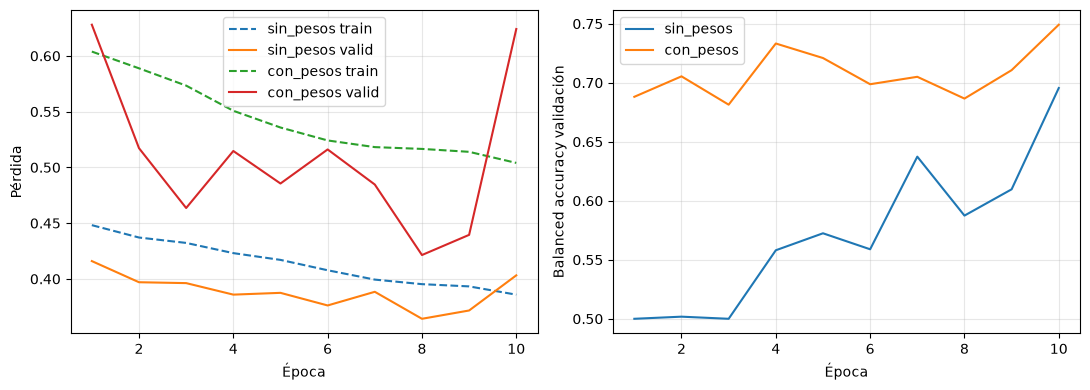

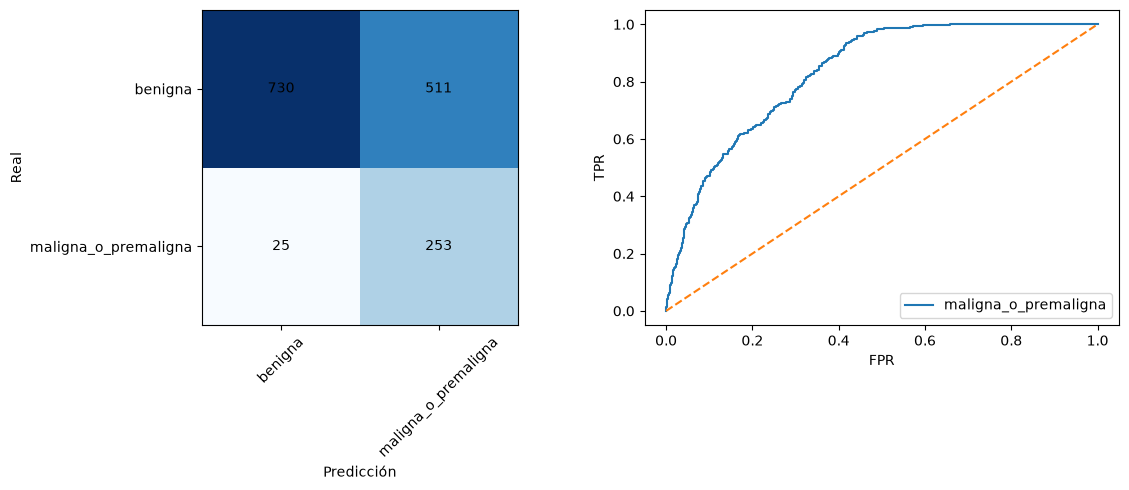

{'balanced_accuracy': 0.7491536182818451,
 'f1_macro': 0.6085337661888075,
 'classification_report': {'benigna': {'precision': 0.9668874172185431,
   'recall': 0.5882352941176471,
   'f1-score': 0.7314629258517034,
   'support': 1241.0},
  'maligna_o_premaligna': {'precision': 0.331151832460733,
   'recall': 0.9100719424460432,
   'f1-score': 0.4856046065259117,
   'support': 278.0},
  'accuracy': 0.6471362738643844,
  'macro avg': {'precision': 0.649019624839638,
   'recall': 0.7491536182818451,
   'f1-score': 0.6085337661888075,
   'support': 1519.0},
  'weighted avg': {'precision': 0.8505381791917681,
   'recall': 0.6471362738643844,
   'f1-score': 0.6864671307413873,
   'support': 1519.0}},
 'auc_roc': 0.8328888863123844,
 'false_negative_rate': {'benigna': 0.4117647058823529,
  'maligna_o_premaligna': 0.08992805755395683}}

In [8]:
plot_history(histories,RUNS/'baseline')
model=SmallCNN().to(DEVICE)
model.load_state_dict(torch.load(Path(selected['folder'])/'best.pt',map_location=DEVICE,weights_only=False)['model'])
display(report(model,frames['valid'],RUNS/'baseline'/'validation_selected'))

## 6. Test final — ejecutar tras fijar los experimentos

La selección anterior usa validación. El test se reserva hasta confirmar el protocolo.

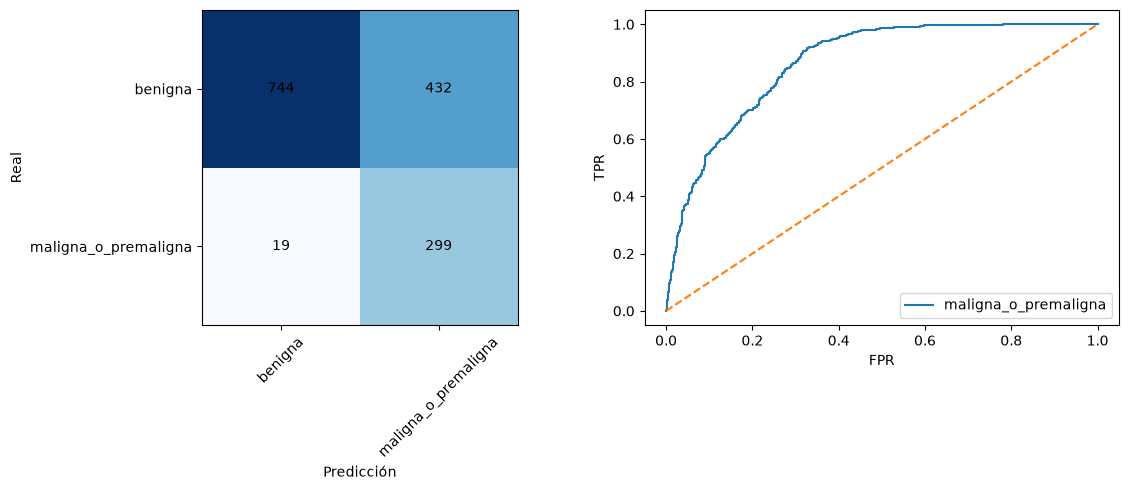

{'balanced_accuracy': 0.7864523167757669,
 'f1_macro': 0.6687363047692466,
 'classification_report': {'benigna': {'precision': 0.9750982961992136,
   'recall': 0.6326530612244898,
   'f1-score': 0.7674058793192368,
   'support': 1176.0},
  'maligna_o_premaligna': {'precision': 0.40902872777017785,
   'recall': 0.940251572327044,
   'f1-score': 0.5700667302192565,
   'support': 318.0},
  'accuracy': 0.6981258366800536,
  'macro avg': {'precision': 0.6920635119846957,
   'recall': 0.7864523167757669,
   'f1-score': 0.6687363047692466,
   'support': 1494.0},
  'weighted avg': {'precision': 0.8546095928789771,
   'recall': 0.6981258366800536,
   'f1-score': 0.72540196404896,
   'support': 1494.0}},
 'auc_roc': 0.8648627690069738,
 'false_negative_rate': {'benigna': 0.36734693877551017,
  'maligna_o_premaligna': 0.05974842767295596}}

In [10]:
RUN_FINAL_TEST=True
if RUN_FINAL_TEST:
    assert MODE=='full', 'Test bloqueado para pruebas smoke.'
    lock=RUNS/'baseline_test_lock.json'
    if lock.exists(): assert json.loads(lock.read_text())==selected, 'La selección cambió después de fijar el test.'
    else: lock.write_text(json.dumps(selected,indent=2))
    destination=RUNS/'final_test'/'baseline'
    if (destination/'metrics.json').exists():
        print('Evaluación final ya guardada:',destination)
    else:
        model=SmallCNN().to(DEVICE)
        state=torch.load(Path(selected['folder'])/'best.pt',map_location=DEVICE,weights_only=False)
        assert state['signature']==selected['signature']; model.load_state_dict(state['model'])
        display(report(model,frames['test'],destination))
else:
    print('Test reservado: activar solo después de fijar configuración y selección por validación.')